# 6.6 - Assessing the strategies: costs, tails, drift, the Fundamental Law, and luck

Notebook 6.5 ran 44 strategies built from four out-of-sample signals. A backtest's headline number answers only one
question. This notebook asks the others *Machine Learning for Trading* (chapters 16-20) asks before any money is
committed:

1. **Costs** - how much of the edge do trading costs take, and how much higher could they be before nothing is left?
2. **Tail risk** - how bad are the worst days?
3. **Drift** - is the signal weakening through time?
4. **The Fundamental Law** - how much of each signal survives into the portfolio, and how many independent bets the
   strategies really made?
5. **Luck** - after trying 44 strategies, is the best one better than the best of 44 lucky ones?

It ends with what the plan's final step - the one look at the hold-out from 2025 - would need, which is left for a
decision rather than taken here.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.research import assessment as asm
from equity_research.research import boosting as gb
from equity_research.research import evaluation as ev
from equity_research.research import labels as lb
from equity_research.research import linear as ln
from equity_research.research import ml_strategy as ms
from equity_research.research import portfolio_risk as pr
from equity_research.research import store
from equity_research.research import validation as va
from equity_research.research.backtest import BacktestResult
from equity_research.research.cache import ResearchCache
from equity_research.research.data import load_universe_data
from equity_research.research.features import unstack
from equity_research.research.indices import vendor_returns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
charts.style()

UNIVERSE, START, END = "SP1500", "2005-01-01", "2024-12-31"
FIRST_TEST, LAST_TEST, TRAIN_YEARS, OPTUNA_TRIALS = 2015, 2024, 10, 40
cache = ResearchCache()
SNAPSHOT = store.data_snapshot(cache)
data = load_universe_data(cache, UNIVERSE, START, END)
dates = data.rebalances
test_dates = dates[(dates.year >= FIRST_TEST) & (dates.year <= LAST_TEST)]
FEATURES = {"universe": UNIVERSE, "start": START, "end": END, "dates": "month ends", "version": 1}
long = store.load("features", "company_month_end", FEATURES, snapshot=SNAPSHOT)
assert long is not None, "run notebooks 6.2-6.5 first"
monthly = store.cached(
    "labels",
    "fwd_ret_month",
    {"universe": UNIVERSE, "start": START, "end": END, "dates": "rebalances"},
    lambda: lb.period_returns(data.returns, dates),
    snapshot=SNAPSHOT,
)
x = ln.centred_ranks(long)
y = lb.trimmed_excess(monthly, data.members)
ends = va.next_date_ends(dates)
folds = va.walk_forward(dates, ends, train_years=TRAIN_YEARS, first_test=FIRST_TEST, last_test=LAST_TEST)
STUDY = FEATURES | {
    "target": "trimmed excess, 1 %",
    "train_years": TRAIN_YEARS,
    "first_test": FIRST_TEST,
    "flat": "ic 0",
}
KEY = STUDY | {"strategies": "P4 v1"}


def slug(name: str) -> str:
    """A strategy's name as a file name."""
    return "".join(c if c.isalnum() else "_" for c in name)


panels = unstack(long)
linear_runs = {
    n: ln.stored_walk_forward(x, y, folds, ends, m, name=n, config=STUDY, snapshot=SNAPSHOT)
    for n, m in ln.MODELS.items()
}
grid_run = gb.stored_walk_forward(x, y, folds, ends, gb.grid(), name="grid", config=STUDY, snapshot=SNAPSHOT)
loss = gb.grid()[str(grid_run.tuning.loc[min(grid_run.tuning.index)].idxmax())].loss
_, best = gb.stored_search(
    x, y, folds[0].train, ends, loss=loss, n_trials=OPTUNA_TRIALS, config=STUDY, snapshot=SNAPSHOT
)
tuned_run = gb.stored_walk_forward(x, y, folds, ends, {"optuna": best}, name="optuna", config=STUDY, snapshot=SNAPSHOT)
signals = {
    "Composite": ln.composite({"issuance": -panels["share_change"], "ROCE": panels["ROCE"]}, data.members),
    "Logistic (6.3)": linear_runs["logistic"].scores,
    "GBM grid (6.4)": grid_run.scores,
    "GBM Optuna (6.4)": tuned_run.scores,
}
signals = {name: s.reindex(index=test_dates, columns=data.returns.columns) for name, s in signals.items()}
summary = store.load("strategy", "summary", KEY, snapshot=SNAPSHOT)
assert summary is not None, "run notebook 6.5 first"
results, books, nets = {}, {}, {}
for name in summary.index:
    daily = store.load("strategy", f"daily-{slug(name)}", KEY, snapshot=SNAPSHOT)
    nets[name] = daily["net"]
    if "gross" in daily:
        results[name] = BacktestResult(daily["gross"], daily["net"], daily["turnover"], daily["costs"], pd.DataFrame())
        books[name] = store.load("strategy", f"book-{slug(name)}", KEY, snapshot=SNAPSHOT)
long_only = {n: n.split(" | ")[1] == "long-only" for n in summary.index}
print(f"{len(nets)} strategies read back; {len(books)} with their books")

left out 887 facts of 2 companies in ['GBP']


44 strategies read back; 32 with their books


## Step 1 - costs: how much of the edge they take, and the break-even

For each of the 32 portfolios: the active return before and after costs (long-only against SPTM, long-short against
cash), the average one-way cost the backtest charged per unit traded, and the **break-even multiple** - how many
times higher costs could be before the active return falls to zero. Below 1, the strategy already loses after costs;
around 2 or less, a small error in the cost assumption would erase it.

In [2]:
benchmark = data.benchmark
zero = pd.Series(0.0, index=benchmark.index)
even = pd.DataFrame({n: asm.break_even(r, benchmark if long_only[n] else zero) for n, r in results.items()}).T
even["turnover"] = summary.loc[even.index, "turnover"]
display(
    even.sort_values("break-even multiple", ascending=False).style.format(
        {
            "gross active": "{:+.2%}",
            "net active": "{:+.2%}",
            "cost charged (bp)": "{:.1f}",
            "break-even multiple": "{:.2f}",
            "break-even cost (bp)": "{:.0f}",
            "turnover": "{:.1f}",
        },
        na_rep="-",
    )
)

,gross active,net active,cost charged (bp),break-even multiple,break-even cost (bp),turnover
Composite | long-short | mean_variance,+11.12%,+7.41%,28.4,2.99,85,9.5
GBM Optuna (6.4) | long-short | mean_variance,+23.49%,+10.95%,27.8,1.87,52,36.4
Logistic (6.3) | long-short | mean_variance,+17.25%,+7.92%,27.9,1.85,52,27.1
Composite | long-short | inverse_vol,+5.82%,+2.56%,29.6,1.78,53,8.2
Composite | long-short | equal,+5.67%,+2.44%,32.1,1.76,56,7.4
GBM grid (6.4) | long-short | mean_variance,+18.64%,+7.66%,26.2,1.70,44,34.8
Logistic (6.3) | long-only | mean_variance,+4.06%,+1.41%,20.2,1.53,31,12.8
Composite | long-short | hrp,+5.67%,+1.82%,27.9,1.47,41,10.9
GBM Optuna (6.4) | long-short | equal,+12.62%,+2.06%,29.6,1.19,35,31.1
GBM Optuna (6.4) | long-short | inverse_vol,+11.44%,+1.25%,27.2,1.12,31,33.2


The cost assumption itself, against an estimate from the data: notebook 6.2's Roll spread (from the bounce of daily
closes) halved - a one-way cost is half the spread - against the cost the backtests charge, by index segment, on the
month ends of the test years. Then the four equal-weighted long-short books rerun at zero to four times the costs.

In [3]:
segment = data.segment.reindex(index=test_dates, columns=data.returns.columns)
on = data.members.reindex(index=test_dates, columns=data.returns.columns, fill_value=False).astype(bool)
spread = panels["roll_spread_3m"].reindex(index=test_dates, columns=data.returns.columns) / 2 * 1e4
charged = data.cost_bps.reindex(index=test_dates, columns=data.returns.columns)
rows = {}
for seg in ("large", "mid", "small"):
    mask = (on & (segment == seg)).to_numpy()
    rows[seg] = {
        "Roll half-spread (bp), median": float(np.nanmedian(spread.to_numpy()[mask])),
        "charged one-way (bp), median": float(np.nanmedian(charged.to_numpy()[mask])),
    }
display(pd.DataFrame(rows).T.style.format("{:.1f}"))
grids = {s: asm.cost_grid(books[f"{s} | long-short | equal"], data, zero, end=pd.Timestamp(END)) for s in signals}
display(pd.concat({s: g["information_ratio"] for s, g in grids.items()}, axis=1).T.style.format("{:+.2f}"))

,"Roll half-spread (bp), median","charged one-way (bp), median"
large,21.9,10.0
mid,25.5,25.0
small,32.8,50.0


cost multiple,0.000000,0.500000,1.000000,2.000000,4.000000
Composite,+0.56,+0.42,+0.28,-0.01,-0.57
Logistic (6.3),+0.60,+0.28,-0.04,-0.68,-1.97
GBM grid (6.4),+0.56,+0.30,+0.04,-0.47,-1.51
GBM Optuna (6.4),+0.82,+0.51,+0.20,-0.42,-1.67


## Step 2 - tail risk

Historical one-day value at risk at 99 % (the loss exceeded on one day in a hundred) and conditional value at risk
(the average loss on those days), over 2015-2024, beside SPTM's.

In [4]:
sptm = vendor_returns(cache, "SPTM", total=True).loc[str(FIRST_TEST) : END]
tails = pd.DataFrame(
    {n: asm.tail_risk(net.loc[str(FIRST_TEST) :]) for n, net in nets.items()} | {"SPTM": asm.tail_risk(sptm)}
).T
tails["entry"] = [("index" if n == "SPTM" else n.split(" | ")[1]) for n in tails.index]
display(
    tails.groupby("entry")[["VaR", "CVaR"]]
    .describe()
    .loc[:, (slice(None), ["min", "50%", "max"])]
    .style.format("{:.2%}")
)

## Step 3 - drift: is each signal weakening?

Each signal's IC over a rolling year, and the linear trend of its monthly IC through 2015-2024 with a t-statistic.

,mean IC,trend a year,t
Composite,+0.0249,+0.0040,+1.60
Logistic (6.3),+0.0236,+0.0009,+0.29
GBM grid (6.4),+0.0286,-0.0061,-1.75
GBM Optuna (6.4),+0.0265,-0.0058,-1.66


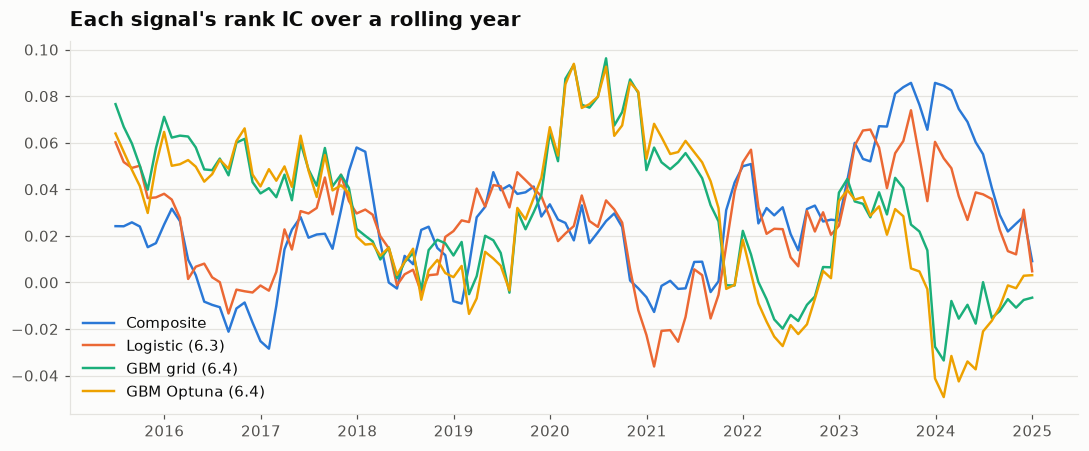

In [5]:
ics = pd.DataFrame({n: ev.ic_series(s, monthly, data.members) for n, s in signals.items()}).loc[test_dates]
drift = {n: asm.ic_drift(ics[n]) for n in ics.columns}
display(
    pd.DataFrame(
        {n: {"mean IC": ics[n].mean(), "trend a year": d["trend a year"], "t": d["t_nw"]} for n, d in drift.items()}
    ).T.style.format({"mean IC": "{:+.4f}", "trend a year": "{:+.4f}", "t": "{:+.2f}"})
)
fig = charts.lines({n: d["rolling"] for n, d in drift.items()}, "Each signal's rank IC over a rolling year")

## Step 4 - the Fundamental Law: how much of each signal reaches the portfolio

The transfer coefficient (TC) of a book is the correlation, across members each month end, between its active
weights and what the signal alone would ask for (score over volatility). The law then predicts an information ratio
of TC x IC x $\sqrt{\text{breadth}}$, with breadth the members times 12. Comparing it with the realised IR gives the
**effective breadth** - $(\text{IR} / (\text{TC} \times \text{IC}))^2$ - the number of independent bets a year the
strategy really made. Long-only books against market-value weights; long-short against zero.

In [6]:
vol = data.returns.rolling(63, min_periods=30).std().reindex(test_dates)
cap = pr.cap_weights(data.market_cap, data.members).reindex(index=test_dates, columns=data.returns.columns).fillna(0.0)
nothing = cap * 0.0
names = float(data.members.reindex(test_dates).sum(axis=1).median())
law = {}
for s in signals:
    for entry in ("long-only", "long-short"):
        for method in ("equal", "mean_variance"):
            n = f"{s} | {entry} | {method}"
            tc = asm.transfer_coefficient(
                books[n], signals[s], vol, data.members, cap if entry == "long-only" else nothing
            )
            ic, ir = float(ics[s].mean()), float(summary.loc[n, "information_ratio"])
            law[n] = {
                "IC": ic,
                "TC": tc.mean(),
                "predicted IR": asm.fundamental_law(ic, names * 12, tc.mean()),
                "realised IR": ir,
                "effective breadth": (ir / (tc.mean() * ic)) ** 2 if ir > 0 and ic > 0 else np.nan,
            }
display(
    pd.DataFrame(law).T.style.format(
        {
            "IC": "{:+.4f}",
            "TC": "{:.2f}",
            "predicted IR": "{:+.2f}",
            "realised IR": "{:+.2f}",
            "effective breadth": "{:,.0f}",
        },
        na_rep="-",
    )
)
print(f"Nominal breadth: {names:,.0f} members x 12 = {names * 12:,.0f} bets a year")

,IC,TC,predicted IR,realised IR,effective breadth
Composite | long-only | equal,+0.0249,0.23,+0.75,-0.01,-
Composite | long-only | mean_variance,+0.0249,0.20,+0.66,+0.08,288
Composite | long-short | equal,+0.0249,0.63,+2.10,+0.26,285
Composite | long-short | mean_variance,+0.0249,0.40,+1.35,+0.70,"4,838"
Logistic (6.3) | long-only | equal,+0.0236,0.30,+0.94,-0.25,-
Logistic (6.3) | long-only | mean_variance,+0.0236,0.30,+0.94,+0.28,"1,572"
Logistic (6.3) | long-short | equal,+0.0236,0.70,+2.23,-0.02,-
Logistic (6.3) | long-short | mean_variance,+0.0236,0.47,+1.51,+0.54,"2,335"
GBM grid (6.4) | long-only | equal,+0.0286,0.31,+1.21,-0.24,-
GBM grid (6.4) | long-only | mean_variance,+0.0286,0.27,+1.03,+0.04,30


Nominal breadth: 1,504 members x 12 = 18,048 bets a year


## Step 5 - luck: the best of many, tested as the best of many

* **White's Reality Check** over all 44 strategies' monthly returns over their benchmark (long-only over SPTM,
  long-short over cash): is the best one's mean more than the best of 44 would reach by luck? The bootstrap keeps
  six-month blocks together. White's version compares raw means, so the most volatile strategies dominate the
  maximum; the studentised version (the step Hansen's SPA test adds) compares t-statistics, so every strategy counts.
* **The Rademacher bound** over the monthly ICs of every out-of-sample signal of 6.3 and 6.4 and the composite: with
  95 % confidence, each signal's true mean IC is at least its lower bound - simultaneously for all of them.
* **Deflated ratios** of 6.5, which count the family's 44 trials.

In [7]:
active = pd.DataFrame(
    {n: ms.monthly_active(net.loc[str(FIRST_TEST) :], benchmark, long_only=long_only[n]) for n, net in nets.items()}
)
for label, studentise in (("raw means (White)", False), ("t-statistics (studentised)", True)):
    rc = asm.reality_check(active, studentise=studentise)
    print(
        f"Reality Check on {label}, {rc['strategies']} strategies, {rc['periods']} months: best '{rc['best']}', "
        f"mean {rc['mean']:+.2%} a month, p-value {rc['p_value']:.3f}"
    )
all_ics = pd.DataFrame(
    {
        n: ev.ic_series(s, monthly, data.members)
        for n, s in (
            {ln.MODELS[k].label: r.scores for k, r in linear_runs.items()}
            | {"GBM grid": grid_run.scores, "GBM Optuna": tuned_run.scores, "Composite": signals["Composite"]}
        ).items()
    }
).loc[test_dates]
bounds = asm.rademacher_bounds(all_ics)
display(bounds.style.format("{:+.4f}"))
display(
    summary[["information_ratio", "deflated"]]
    .sort_values("deflated", ascending=False)
    .head(10)
    .style.format({"information_ratio": "{:+.2f}", "deflated": "{:.0%}"})
)

Reality Check on raw means (White), 44 strategies, 119 months: best 'GBM Optuna (6.4) | long-short | mean_variance', mean +1.11% a month, p-value 0.049


Reality Check on t-statistics (studentised), 44 strategies, 119 months: best 'Composite | long-short | mean_variance', mean +0.64% a month, p-value 0.129


,mean,rademacher,slack,lower bound
Ridge,+0.0139,+0.0090,+0.7470,-0.7510
Lasso,+0.0053,+0.0090,+0.7470,-0.7595
Elastic net,+0.0087,+0.0090,+0.7470,-0.7561
Logistic regression,+0.0236,+0.0090,+0.7470,-0.7412
GBM grid,+0.0286,+0.0090,+0.7470,-0.7363
GBM Optuna,+0.0265,+0.0090,+0.7470,-0.7384
Composite,+0.0249,+0.0090,+0.7470,-0.7400


,information_ratio,deflated
Composite | long-short | mean_variance,+0.70,49%
Logistic (6.3) | long-short | mean_variance,+0.54,30%
GBM Optuna (6.4) | long-short | mean_variance,+0.53,29%
GBM grid (6.4) | long-short | mean_variance,+0.40,17%
Composite | long-short | inverse_vol,+0.32,11%
Logistic (6.3) | long-only | mean_variance,+0.28,9%
Composite | long-short | equal,+0.26,8%
Composite | long-short | hrp,+0.25,8%
GBM Optuna (6.4) | long-short | equal,+0.21,6%
GBM Optuna (6.4) | long-short | inverse_vol,+0.16,4%


## Step 6 - the hold-out: what remains, and why it is not taken here

The plan ends with one look at the data from 2025 onward, which no notebook has touched: refit the chosen
configuration on all history before 2025, trade 2025 to date once, and record the result in the registry with the
hold-out marked open. It can be done only once: a second look, after adjusting anything, would be another trial on
data that has then been seen.

What that step needs is a **decision**: which single strategy, if any, deserves it. The evidence above is the basis
for that decision, and the notebook leaves it to the owner of the research rather than taking it.

## Findings

**In short: no strategy of 6.5 passes as more than luck once the 44 tries are counted, and the ones with a cushion
against costs are few.** The strongest candidate for the hold-out is the composite of issuance and ROCE, long-short
with mean-variance weights: the widest cost margin, the steadiest signal and the best deflated ratio - and even it is
short of evidence.

**1. Costs (step 1).** Of the 32 portfolios, 12 earn more than their benchmark after costs.

* **The margins are thin** - the break-even multiple says how many times higher costs could be before the edge is
  gone. Only the composite's long-short mean-variance book reaches 3.0 (it would break even at 85 basis points a
  trade against the 28 charged). The models' best long-short books break even at 1.7-1.9 times the costs, and the
  best long-only book, logistic with mean-variance weights, at 1.5.
* **Costs reorder the signals** - the four equal-weighted long-short books, rerun at several cost levels:

| Signal | Sharpe at no cost | at the charged cost | at twice the cost |
|---|---|---|---|
| GBM Optuna (6.4) | +0.82 | +0.20 | -0.42 |
| Logistic (6.3) | +0.60 | -0.04 | -0.68 |
| GBM grid (6.4) | +0.56 | +0.04 | -0.47 |
| Composite | +0.56 | +0.28 | -0.01 |

  Before costs the boosted signal is best; at the costs charged, the composite, which trades least, is. At twice
  the costs, none earns anything.
* **Are the costs right?** Half of Roll's spread, estimated from the bounce of daily closes, has a median of 22
  basis points for large companies (10 charged), 26 for mid-sized (25 charged) and 33 for small (50 charged). Roll's
  estimate is noisy - any negative autocorrelation of daily returns, not only the bid-ask bounce, raises it - so it
  cannot settle the question. It does say that the large-company cost of 10 basis points is not obviously generous.

**2. Tail risk (step 2).** SPTM's one-day 99 % value at risk over 2015-2024 was 3.2 %, the average loss on those
days (CVaR) 4.6 %. The long-only strategies were close to it (VaR 2.7-3.9 %, CVaR 3.7-5.5 %). The long-short ones
were usually calmer (median VaR 2.2 %, CVaR 3.0 %), but the highest VaR was 4.5 % and the highest CVaR 8.8 %: on its
worst days that strategy lost about twice what the index did.

**3. Drift (step 3).** The trend of each signal's monthly IC through the ten test years:

* **Composite** - +0.004 a year (t +1.60): steady or strengthening.
* **Logistic** - +0.001 a year (t +0.29): flat.
* **Gradient boosting** - -0.006 a year for both versions (t -1.75 and -1.66): weakening, though not significantly.
  The bad 2023 of 6.4 is part of it.

**4. The Fundamental Law (step 4).** The law predicts an information ratio of TC x IC x the square root of breadth.

* **Transfer coefficient** - long-short equal-weighted books pass 0.63-0.70 of their signal into the portfolio;
  long-only books only 0.20-0.31, because a long-only book cannot hold less than nothing of the companies it
  dislikes.
* **Predicted against realised** - with 1,504 members a month (18,048 bets a year) the law predicts IRs of +0.66 to
  +2.64. The realised IRs were -0.25 to +0.70. Part of the gap is costs (the law's figure is before them), but most
  is breadth: the bets are not independent.
* **Effective breadth** - the realised IRs imply from 8 to 4,838 independent bets a year, against 18,048 nominal.
  Companies move together - by sector, by style - and a month's ranking repeats much of the last month's, so far
  fewer independent bets are made than names are ranked.

**5. Luck (step 5).** Three tests, one answer.

* **White's Reality Check** - on raw monthly means over the benchmark, the best of the 44 is gradient boosting's
  long-short mean-variance book (+1.11 % a month), with a p-value of 0.049. That looks like evidence, but White's
  statistic compares raw means, so the most volatile strategies dominate the maximum and the 43 calmer ones hardly
  count as tries.
* **Studentised** - compared by t-statistic instead (the step Hansen's SPA test adds), every strategy counts, the
  best is the composite's long-short mean-variance book (+0.64 % a month), and the p-value is 0.129: not
  distinguishable from the best of 44 lucky strategies.
* **Deflated ratios** - the same book has the best, 49 %; the next are logistic and GBM Optuna long-short
  mean-variance (30 % and 29 %); no long-only strategy exceeds 9 %.
* **The Rademacher bound** - true, and here uninformative. Its sampling term, with ICs allowed anywhere from -1 to
  +1, is 0.75 for 119 months: every lower bound is near -0.75. It would need over a hundred thousand periods to fall
  to 0.02. Its other term is still telling: the complexity of choosing among these seven signals alone is worth
  0.018 of IC (twice 0.009), which would leave GBM grid +0.011, GBM Optuna +0.009, the composite +0.007 and logistic
  +0.006, and the three penalised regressions below zero.

**6. What this means for the hold-out (step 6).** The research has not found a strategy that clears the bar for
evidence: the best deflated ratio is 49 %, the studentised Reality Check's p-value 0.13. Opening 2025 onward is still
useful - as an honest out-of-sample record of the candidate the evidence favours most, the composite long-short
mean-variance book (or, for a long-only mandate, logistic with mean-variance weights) - provided it is done once, with
the configuration fixed beforehand and the result recorded whatever it is. Whether to do it, and with which
strategy, is the decision this notebook leaves open.

## Glossary

* **Break-even cost** - the trading cost at which a strategy's edge over its benchmark would be zero.
* **Value at risk (VaR) / conditional VaR** - the loss exceeded on a given share of days, and the average loss on
  those days.
* **Transfer coefficient** - the correlation between a portfolio's active weights and the weights its forecasts
  alone would ask for.
* **Effective breadth** - the number of independent bets a year that the realised IR implies.
* **White's Reality Check** - a bootstrap test of whether the best of many strategies beats its benchmark by more than
  the best of as many lucky strategies would.
* **Rademacher complexity** - how well the best of a set of signals can correlate with pure noise: a measure of how
  much choosing among them can flatter the winner.
* **Hold-out** - data set aside and not looked at until the research is finished, to test the final choice once.